# A Library RAG Lab: Follow the Evidence

This lesson follows one question:

> How many books can a student borrow at a time, for how long, and how can they renew them?

Open the [two-page Library Borrowing Guide](../data/library-guide.pdf) and find the answer yourself. Then watch the program do the same job: **organize the material for retrieval, find the evidence, and ask a model to compose an answer.**

We will follow just two pieces of evidence throughout the lesson. You do not need to memorize every field or API name.

| Evidence to follow | Location in the PDF | Part of the question it answers |
| --- | --- | --- |
| **Table evidence:** 3 books, 14 days | Page 1 | How many books? For how long? |
| **Text evidence:** renew once for 7 extra days if nobody else has reserved the book | Page 2 | How does renewal work? What are the conditions? |

**How to use this lesson:** Each code cell performs one operation or displays one result. The bold label above it names the source of that result. Cells marked **Run** save values silently; cells marked **Inspect** use one `print(...)` or `display(...)`. Setup and function-definition cells can have no output.

Change a list index to inspect one item at a time. The cells in Step 7 let you read a search message, a passage, and its source individually. In Step 9 you can see whether LightRAG reused a saved answer.

Sections 1–3 prepare the components, sections 4–6 build the index, sections 7–9 unpack the question-answering process, and section 10 covers saving and rerunning. See the [README](../README.md) for installation and startup. Rerunning ingestion or queries can call cloud models; reading saved results does not call a model.

## Start with a map; you do not need to memorize every arrow

```mermaid
flowchart TD
    subgraph INDEX["Phase 1: Ingest the document and build reusable indexes"]
        PDF["Two-page library PDF"] --> PARSE["Docling parses text, a table, and an image"]
        PARSE --> CHUNKS["Split text; describe the table and image"]
        CHUNKS --> TEXT["Store chunk content and provenance"]
        CHUNKS --> VECTOR["Generate chunk embeddings"]
        CHUNKS --> GRAPH["Extract entities and relationships; build graph and vector indexes"]
    end
    subgraph QUERY["Phase 2: Retrieve evidence and answer a question"]
        Q["How many books, for how long, and how to renew?"] --> SEARCH["mix: vector and graph retrieval"]
        SEARCH --> EVIDENCE["Retrieve relevant chunks and combine evidence"]
        EVIDENCE --> PROMPT["Instructions + evidence + original question"]
        PROMPT --> ANSWER["Answer: 3 books, 14 days, renewal steps and conditions"]
        ANSWER --> REF["Include source references"]
    end
    VECTOR --> SEARCH
    GRAPH --> SEARCH
    TEXT --> EVIDENCE
```

**Ingestion can finish before any question arrives.** Parsing a PDF and building an index do not train or change the answer model. We will add caching to this main path in section 9.

By the end, you should be able to explain three things without reading the code:

1. How do “3 books” and “14 days” travel from the PDF table into the answer?
2. What do vectors and the knowledge graph each help the system find?
3. Which model call is avoided when a repeated question hits the cache?

The saved examples show the original run that built the library index. If you ingest the document again, model descriptions, graph contents, and some IDs may change. Use the new outputs as the source of truth.

## 1. Prepare: Locate the source and choose a storage directory

**Question for this step: Which file will the program read, and where will it save the index?** No parsing, ingestion, or querying has happened yet.

| Setting | Meaning in this lesson |
| --- | --- |
| `pdf_path` | The source file, `data/library-guide.pdf` |
| `parsed_dir` | Files and images exported by Docling |
| `storage_dir` | Persistent chunks, vectors, graph, and caches |
| Model names, endpoint, and dimensions | Which cloud models receive which tasks |

Start JupyterLab from the project root with `src/.env` loaded. The code searches upward for the directory containing `pyproject.toml`, so it can locate the PDF even when the notebook is inside `src/`.

**After running, check only:** the source filename is `library-guide.pdf`, and the index directory is `outputs/library_rag_storage`. You do not need to study every import yet.

**Locate the project**

Find the PDF and the folders for parsed content and the searchable index.

In [1]:
import os
from pathlib import Path

cwd = Path.cwd().resolve()
project_dir = next((p for p in (cwd, *cwd.parents) if (p / "pyproject.toml").is_file()), None)
if project_dir is None:
    raise FileNotFoundError("Project root not found. Start JupyterLab from the project root.")

pdf_path = project_dir / "data/library-guide.pdf"
parsed_dir = project_dir / "outputs/parsed"
storage_dir = project_dir / "outputs/library_rag_storage"

**Import the RAG components**

Load the parser, model callbacks, and search tools. Keep LightRAG’s progress in memory so each inspection cell can show one result.

In [2]:
from io import StringIO
import logging
from IPython.utils.capture import capture_output

with capture_output():
    from collections import Counter
    from IPython.display import Image, Markdown, display
    from lightrag import QueryParam
    from lightrag.llm.openai import openai_complete_if_cache, openai_embed
    from lightrag.utils import EmbeddingFunc
    from raganything import RAGAnything, RAGAnythingConfig, set_prompt_language
    from raganything.prompt import PROMPTS

# Steps 7 and 9 use these messages to show what LightRAG did.
rag_progress = StringIO()
progress_handler = logging.StreamHandler(rag_progress)
progress_handler.setFormatter(logging.Formatter("%(funcName)s | %(message)s"))
logging.getLogger("lightrag").handlers = [progress_handler]

**Prepare: read model settings**

Reads the environment loaded when Jupyter started. No credentials are printed.

In [3]:
from dotenv import load_dotenv

load_dotenv(project_dir / "src/.env")
api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("OPENAI_BASE_URL")
llm_model = os.getenv("LLM_MODEL")
vision_model = os.getenv("VISION_MODEL")
embedding_model = os.getenv("EMBEDDING_MODEL")
embedding_dim = int(os.environ["EMBEDDING_DIM"])

**Inspect: source filename**

Output source: `pdf_path.name` from the preparation cells.

In [4]:
print(pdf_path.name)

library-guide.pdf


**Inspect: parser output directory**

Output source: `parsed_dir` from the preparation cells.

In [5]:
print(parsed_dir)

/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed


**Inspect: index directory**

Output source: `storage_dir` from the preparation cells.

In [6]:
print(storage_dir)

/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage


**Inspect: text model name**

Output source: `llm_model` from the preparation cells.

In [7]:
print(llm_model)

gpt-6-luna


**Inspect: vision model name**

Output source: `vision_model` from the preparation cells.

In [8]:
print(vision_model)

gpt-6-luna


**Inspect: embedding model name**

Output source: `embedding_model` from the preparation cells.

In [9]:
print(embedding_model)

text-embedding-3-small


**Inspect: embedding dimensions**

Output source: `embedding_dim` from the preparation cells.

In [10]:
print(embedding_dim)

1536


## 2. Prepare: Separate the three model roles

**Question for this step: Who interprets content, and who turns text into numbers?** The following cells define callback functions separately. Defining them does not send a model request.

```mermaid
flowchart LR
    T["Text, table structure, or an extraction task"] --> L["llm: text model"] --> O["Analysis, entities, relationships, keywords, or an answer"]
    I["Image and related text"] --> V["vision: vision model"] --> D["Text description of the image"]
    S["A batch of texts"] --> E["embed: embedding model"] --> N["One numeric vector per text"]
```

`calls` is the current kernel's **model call log**. Each callback records its input and output so that we can inspect what happened. It is not the persistent cache; resetting this list does not clear cached results on disk.

**Remember these roles:** `llm` interprets and generates text; `vision` interprets images; `embed` encodes text. The text model extracts entities and relationships. Embedding alone does not build a graph or write a summary.

The callback implementations are long and are collapsed by default. On your first pass, run the definition cells and use `calls` later to inspect the work.

<details>
<summary>Optional detail: Why are these functions relatively long?</summary>

They both call the official OpenAI helper functions and record inputs and outputs. Vision records show image types and URL lengths; section 4 displays the actual image. Embedding records show input texts, the output shape, and the first six coordinates of the first vector. The next section uses `EmbeddingFunc` to declare the model and dimensions; `openai_embed.func` passes the configured dimensions to the API.

</details>

**Prepare: start the model-call record**

`calls` will store model inputs and outputs in this kernel. Initializing it prints nothing.

In [11]:
calls = []

**Define: `llm(...)`**

Defines one callback; no model request is sent until another function calls it.

In [12]:
async def llm(prompt, system_prompt=None, history_messages=None, **kwargs):
    call = {
        "kind": "llm",
        "model": llm_model,
        "prompt": prompt,
        "system_prompt": system_prompt,
        "history_messages": history_messages or [],
        "keyword_extraction": kwargs.get("keyword_extraction", False),
    }
    calls.append(call)
    output = await openai_complete_if_cache(
        llm_model, prompt, system_prompt=system_prompt,
        history_messages=history_messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    call["output"] = output
    return output

**Define: `vision(...)`**

Defines one callback; no model request is sent until another function calls it.

In [13]:
async def vision(prompt, system_prompt=None, image_data=None, messages=None, **kwargs):
    # Image ingestion passes base64-encoded Docling PNG data; image-enhanced queries pass full messages.
    if messages is None:
        messages = []
        if system_prompt:
            messages.append({"role": "system", "content": system_prompt})
        content = prompt
        if image_data:
            content = [
                {"type": "text", "text": prompt},
                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_data}"}},
            ]
        messages.append({"role": "user", "content": content})

    summary = []
    image_count = 0
    for message in messages:
        content = message["content"]
        if isinstance(content, list):
            parts = []
            for part in content:
                if part["type"] == "image_url":
                    parts.append({"type": "image_url", "url_chars": len(part["image_url"]["url"])})
                    image_count += 1
                else:
                    parts.append(part)
            content = parts
        summary.append({"role": message["role"], "content": content})

    call = {"kind": "vision", "model": vision_model, "messages": summary, "images": image_count}
    calls.append(call)
    output = await openai_complete_if_cache(
        vision_model, "", messages=messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    call["output"] = output
    return output

**Define: `embed(...)`**

Defines one callback; no model request is sent until another function calls it.

In [14]:
async def embed(texts):
    call = {"kind": "embed", "model": embedding_model, "texts": list(texts)}
    calls.append(call)
    vectors = await openai_embed.func(
        texts, model=embedding_model, base_url=base_url, api_key=api_key,
        embedding_dim=embedding_dim, max_token_size=8192,
    )
    call["output"] = {"shape": vectors.shape, "first_vector_sample": vectors[0, :6].tolist()}
    return vectors

## 3. Prepare: Connect the components through RAGAnything

**Question for this step: Who connects the parser, models, and indexes?**

| Component | Role in this lesson |
| --- | --- |
| Docling | Recognizes text, a table, and an image in the PDF |
| RAGAnything | Coordinates multimodal processing and sends content through ingestion and querying |
| LightRAG | Splits text, manages vector and graph indexes, retrieves evidence, and coordinates answer generation |

This project uses LightRAG, which follows a graph-assisted retrieval approach. It does not separately invoke Microsoft's GraphRAG package.

**Before running, notice two settings:** `chunk_token_size=75` and `chunk_overlap_token_size=20`. They will determine how the ordinary text becomes overlapping chunks. A token is a unit used by a model's tokenizer; it is not necessarily a whole word or character.

The next cell creates `rag` and selects English prompts. It does not ingest the PDF yet. On your first pass, just confirm the `docling` parser, the three model callbacks, and the 75/20 chunking settings. We will inspect their effect in section 5.

**Create the RAGAnything instance**

The configured parser, model callbacks, and storage directory belong to `rag`.

In [15]:
with capture_output():
    set_prompt_language("en")

    config = RAGAnythingConfig(
        parser="docling",
        parser_output_dir=str(parsed_dir),
        working_dir=str(storage_dir),
        display_content_stats=False,
    )

    rag = RAGAnything(
        config=config,
        llm_model_func=llm,
        vision_model_func=vision,
        embedding_func=EmbeddingFunc(
            embedding_dim=embedding_dim,
            max_token_size=8192,
            model_name=embedding_model,
            func=embed,
        ),
        lightrag_kwargs={
            "llm_model_name": llm_model,
            "chunk_token_size": 75,
            "chunk_overlap_token_size": 20,
            "addon_params": {"language": "English"},
        },
    )

## 4. Parse: Turn a PDF into typed content with provenance

**Question for this step: What does the program receive for text, a table, and an image?**

```mermaid
flowchart LR
    PDF["Two-page PDF"] --> D["Local Docling parsing"]
    D --> ID["doc_id: document identifier"]
    D --> T["21 text blocks"]
    D --> TB["1 table block"]
    D --> I["1 image block"]
```

**Input → operation → output:** PDF → `parse_document` → `content_list` and `doc_id`.

**Predict before running:** “3 books” and “14 days” should appear in a table block. The renewal condition and “7 extra days” should appear in text on page 2. The next cell parses the material; it does not generate an answer or compute embeddings.

**Use the separate inspection cells to find two things:**

1. The type counts: `text: 21, table: 1, image: 1`.
2. The original text describing when a book can be renewed, and its `page_idx`.

The PDF has a text layer, so OCR is disabled. On its first run, Docling may still download local layout or table-recognition models. This example has no equations. In a document containing equations, any `equation` blocks recognized by the parser can enter the later multimodal processing stage.

**Parse the PDF**

`rag.parse_document` returns the parsed blocks and a document ID.

In [16]:
with capture_output():
    content_list, doc_id = await rag.parse_document(str(pdf_path), allow_ocr=False)

**Inspect: document ID**

Output source: the second value returned by `rag.parse_document(...)`.

In [17]:
print(doc_id)

doc-501ac0a4b56d2d98331eb3d9164f0dfd


**Inspect: parsed block counts**

Output source: `Counter` counts the types in `content_list`.

In [18]:
display(dict(Counter(block["type"] for block in content_list)))

{'text': 21, 'table': 1, 'image': 1}

**Inspect: one parsed block**

Output source: `content_list[block_index]`. Index 14 in the saved run is the renewal condition. Change the index to inspect a different block.

In [19]:
block_index = 14
display(content_list[block_index])

{'type': 'text',
 'text': 'If nobody else has reserved it, renew once for 7 extra days.',
 'page_idx': 1}

**Inspect: image-block metadata**

Output source: the image record in `content_list`. This shows the path; the next cell renders the image.

In [20]:
image_block = next((block for block in content_list if block["type"] == "image"), None)
display(image_block if image_block else "No image block was parsed.")

{'type': 'image',
 'img_path': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed/library-guide_39d2f00c/library-guide/docling/images/image_0.png',
 'image_caption': ['Figure 1. Renewal steps'],
 'image_footnote': [],
 'page_idx': 1}

**Inspect: the extracted image**

Output source: `Image(...)` opens the path from `image_block`. Exactly one image is displayed.

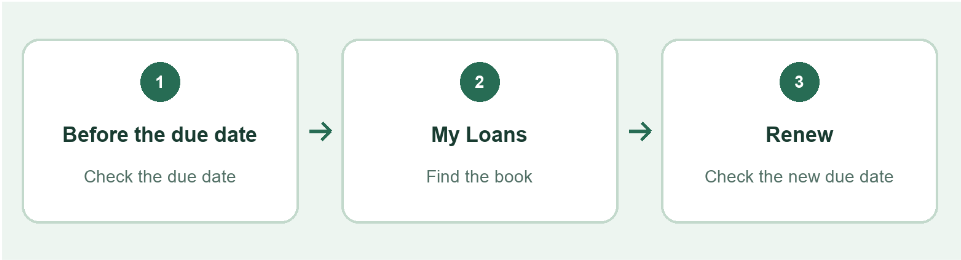

In [21]:
display(Image(filename=image_block["img_path"], width=520) if image_block else "No image to display.")

### 4.1 Understand one parsed block before reading the full list

A parsed text block has this shape. The sentence below illustrates the renewal rule; inspect the output above for the exact parsed wording.

```json
{
  "type": "text",
  "text": "If nobody else has reserved the book, you may renew it once for 7 extra days.",
  "page_idx": 1
}
```

`page_idx=1` means page **2**, because page indices start at zero. A table block stores cell structure in `table_body`; an image block's `img_path` points to an extracted PNG.

The 21 text blocks also include headings, captions, and page numbers. The count does not mean there are 21 complete rules.


**Pause and predict — Check 1: Do we already have 23 chunks and 23 vectors?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

**Not yet.** We have 23 parsed blocks representing the PDF's content and layout. Ingestion will join and split the ordinary text, then process the table and image. This run ultimately produces 6 chunks.

If you answered “yes,” you are mixing up **parsed layout elements** and **retrieval units**. Follow the same evidence from section 4 into section 5.

</details>

## 5. Ingest: Unpack the work behind one function call

**Question for this step: How does parsed content become material we can search later?** `insert_content_list` looks like one call, but it coordinates all of the work below.

```mermaid
flowchart TD
    INPUT["23 parsed blocks"] --> T["21 text blocks"]
    INPUT --> TABLE["1 table"]
    INPUT --> IMAGE["1 image"]
    T --> JOIN["Join ordinary text: 180 tokens"]
    JOIN --> SPLIT["Window: 75 tokens; overlap: 20 tokens"]
    SPLIT --> FOUR["4 text chunks"]
    TABLE --> LLM["Text model analyzes table structure and nearby text"]
    LLM --> TC["Table chunk: 1941 tokens"]
    IMAGE --> VLM["Vision model describes the image"]
    VLM --> IC["Image chunk: 430 tokens"]
    FOUR --> STORE["Store 6 chunks and their provenance"]
    TC --> STORE
    IC --> STORE
```

Table analysis receives table structure and nearby text. Image analysis receives the image and related text. Their generated descriptions also enter the text-based retrieval system. Calling this entire stage “embedding” would hide these separate tasks.

**First, understand the text windows.** The joined ordinary text contains 180 tokens in this run. A 75-token window with a 20-token overlap advances by 55 tokens each time.

| Text chunk | Token range | Length | Overlap with previous chunk |
| --- | --- | ---: | --- |
| 1 | 1–75 | 75 | None |
| 2 | 56–130 | 75 | 56–75 |
| 3 | 111–180 | 70 | 111–130 |
| 4 | 166–180 | 15 | 166–180 |

The final chunk has only 15 tokens and is entirely contained in the end of chunk 3. This last pair therefore shares 15 tokens; 20 is the configured overlap for full windows.

Overlap repeats text near a boundary in adjacent chunks, reducing the chance that a split loses important context. Compare the end of one text chunk with the beginning of the next. Token windows do not guarantee complete sentences, and a chunk can cross a page boundary.

**After running, check the status only:** `fully_processed` should be `True`; this saved run has `chunks_count=6`. A successful `insert_content_list` call returns `None`. The subsequent `status` record tells us whether processing finished.


**Pause and predict — Check 2: Does the second text chunk start at token 56 or 76? Why can the table chunk exceed 75 tokens?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

It starts at **56**, because the stride is `75 - 20 = 55`. The 75-token window applies to ordinary text. Tables and images use separate processing paths, so their chunks may be longer.

If you chose 76, revisit overlap. If you expected the table chunk to stay below 75 tokens, trace the three content branches in the diagram.

</details>

**Index the parsed material**

`rag.insert_content_list` builds or reuses the index. The two positions in `calls` tell us which model calls happened during ingestion.

In [22]:
if not api_key:
    raise RuntimeError("Set OPENAI_API_KEY in src/.env and start Jupyter with that environment loaded.")

before_insert = len(calls)
with capture_output():
    await rag.insert_content_list(content_list, file_path=str(pdf_path), doc_id=doc_id)
after_insert = len(calls)

**Run: `rag.get_document_processing_status(...)`**

Reads the document status into `status`. Raises an error if ingestion did not finish.

In [23]:
with capture_output():
    status = await rag.get_document_processing_status(doc_id)
if not status["fully_processed"]:
    raise RuntimeError("Ingestion is incomplete. Check status['raw_status'] for the document error.")

**Inspect: did ingestion finish?**

Output source: `status["fully_processed"]`.

In [24]:
print(status["fully_processed"])

True


**Inspect: number of stored chunks**

Output source: `status["chunks_count"]`.

In [25]:
print(status["chunks_count"])

6


**Inspect: the full status record (optional)**

Output source: the single record returned by `get_document_processing_status(...)`.

In [26]:
display(status)

{'exists': True,
 'text_processed': True,
 'multimodal_processed': True,
 'fully_processed': True,
 'chunks_count': 6,
 'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9',
  'chunk-f74d3981177947bc583a0860d03ffe3f',
  'chunk-b5b66dc4cdc65aee472efcef7cbf0db9',
  'chunk-0bec09cbf50b78e30405fdc3229058fb',
  'chunk-cf352990e5eade4fe4af96431997ef38',
  'chunk-816ab159240b772497183b1cde78b387'],
 'status': <DocStatus.PROCESSED: 'processed'>,
 'updated_at': '2026-11-18T06:16:14+00:00',
 'raw_status': {'status': <DocStatus.PROCESSED: 'processed'>,
  'chunks_count': 6,
  'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9',
   'chunk-f74d3981177947bc583a0860d03ffe3f',
   'chunk-b5b66dc4cdc65aee472efcef7cbf0db9',
   'chunk-0bec09cbf50b78e30405fdc3229058fb',
   'chunk-cf352990e5eade4fe4af96431997ef38',
   'chunk-816ab159240b772497183b1cde78b387'],
  'content_summary': 'Library Borrowing Guide\n\nBorrowing and returning books\n\nBefore borrowing, check that your account is eligible.\n\nT

### 5.1 Distinguish interpreting content from encoding content

The following inspection cells each show one part of a model call recorded during ingestion. Table instructions, table input, table output, vision input, vision output, embedding input, and embedding output have separate cells. **Compare these two kinds of result:**

- An image or table description is readable text, such as an explanation of the renewal diagram.
- An embedding result is a `shape` and a numeric sample. For example, `(N, 1536)` means N vectors, each with 1536 dimensions.

In this example, the table chunk explains the 3-book limit and 14-day loan period. The image chunk describes the renewal steps. Descriptions may incorporate nearby text, so return to the PDF when checking a fact.

If this run reused an already processed document or cached results, there may be fewer new calls, or no sample for a particular task. An empty `calls` list alone does not show that ingestion failed; also inspect the completion status.


**Pause and predict — Check 3: Who extracts entities and relationships from “renewal adds 7 days,” and who turns text into numbers?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

The text model extracts entities and relationships. The embedding model encodes the supplied text as vectors. The vision model interprets images.

If you thought one embedding call did everything, return to section 2 and separate **interpretation and generation by an LLM/VLM** from **encoding by an embedding model**.

</details>

**Select: model calls made during ingestion**

Selects samples from this ingestion only. Reusing a cached index can leave a sample as `None`. Selection prints nothing.

In [27]:
index_calls = calls[before_insert:after_insert]
table_sample = next((call for call in index_calls if call.get("system_prompt") == PROMPTS["TABLE_ANALYSIS_SYSTEM"]), None)
vision_sample = next((call for call in index_calls if call["kind"] == "vision"), None)
embedding_sample = next((call for call in index_calls if call["kind"] == "embed"), None)

**Inspect: ingestion model-call counts**

Output source: `Counter` summarizes the kinds in `index_calls`.

In [28]:
display(dict(Counter(call["kind"] for call in index_calls)))

{}

**Inspect: table-analysis instructions**

Output source: `table_sample["system_prompt"]`, recorded by the `llm` callback.

In [29]:
print(table_sample.get("system_prompt", "No response recorded.") if table_sample else "No new table-analysis call was recorded.")

No new table-analysis call was recorded.


**Inspect: table-analysis input**

Output source: `table_sample["prompt"]`, recorded by the `llm` callback.

In [30]:
print(table_sample.get("prompt", "No response recorded.") if table_sample else "No new table-analysis call was recorded.")

No new table-analysis call was recorded.


**Inspect: table-analysis response**

Output source: `table_sample["output"]`, recorded by the `llm` callback.

In [31]:
print(table_sample.get("output", "No response recorded.") if table_sample else "No new table-analysis call was recorded.")

No new table-analysis call was recorded.


**Inspect: one vision input message**

Output source: `vision_sample["messages"][vision_message_index]`, recorded by `vision`. Image data is represented by its length; section 4 shows the actual image.

In [32]:
vision_message_index = 0
display(vision_sample["messages"][vision_message_index] if vision_sample else "No new vision call was recorded.")

'No new vision call was recorded.'

**Inspect: vision response**

Output source: `vision_sample["output"]`, recorded by `vision`.

In [33]:
print(vision_sample.get("output", "No response recorded.") if vision_sample else "No new vision call was recorded.")

No new vision call was recorded.


**Inspect: one embedding input text**

Output source: `embedding_sample["texts"][embedding_text_index]`, recorded by `embed`. A request can contain several texts; inspect one at a time.

In [34]:
embedding_text_index = 0
print(embedding_sample["texts"][embedding_text_index] if embedding_sample else "No new embedding call was recorded.")

No new embedding call was recorded.


**Inspect: embedding response summary**

Output source: `embedding_sample["output"]`. The callback saves the array shape and a short vector sample.

In [35]:
display(embedding_sample.get("output", "No response recorded.") if embedding_sample else "No new embedding call was recorded.")

'No new embedding call was recorded.'

## 6. Open what the system saved

**Step 5 saved the information. Step 6 reads it back.** This step does not ask a question or write an answer.

We will follow one sentence from the PDF:

> If nobody else has reserved it, renew once for 7 extra days.

Here, **renew** means asking to keep the book longer. The sentence gives both a condition and a time limit. We want the system to keep that information so it can answer a question later.

### First: the chunk is still readable text

A **chunk** is a saved piece of text. Our sentence is part of a chunk. Making a vector does not remove the text.

Each chunk also has an **ID**. An ID is a label used to find that particular chunk. The label itself is not a summary of the text.

Here is a simplified view of one real saved chunk. The ID and text are shortened for reading:

```text
ID:   chunk-f74d3981…
Text: … Open My Loans, find the book, and click "Renew".
      If nobody else has reserved it, renew once for 7 extra days. …
```

### Second: the vector is a list of numbers used for matching

The embedding model takes the chunk's text and produces numbers. That list is its **vector**, also called an **embedding**.

Later, the system can use these numbers to find text related to a question. For example, “Can I keep the book longer?” may match the renewal text, even though the words differ. This is an illustration, not an extra query run by this cell.

```mermaid
flowchart TD
    ID["A chunk ID links two saved records"] --> T["Text: words a person or answer model can read"]
    ID --> V["Vector: numbers used to find related content"]
```

**Focus on what the numbers are for. You do not need to read meaning from each number.** The answering model will later read the selected text, not the vector's numbers.

### How to read the next output

The loading cell reads the chunks silently. Choose `chunk_index` in the selection cell; the following cells show that chunk's ID, metadata, text, and vector separately. If you change the selection, rerun its dependent inspection and vector-loading cells.

| If you see this | Read it as |
| --- | --- |
| The selected chunk ID | The label for this saved piece of text |
| A paragraph under that label | The text is still available to read |
| `dimensions: 1536` | This vector contains 1536 numbers |
| `sample: [...]` | Only the first six numbers are shown |

**Your task:** Find the sentence about “7 extra days.” Then find the vector record with the same chunk ID. Seeing the same ID is enough; leave the individual numbers aside.

<details>
<summary>Optional: where is this chunk in the PDF?</summary>

This saved chunk spans pages 1–2. Its fields are `page_idx=0` and `page_idx_end=1`, because page indices start at zero. The renewal sentence itself is on PDF page 2. We will follow these source details in section 7.1.

</details>

<details>
<summary>Optional: why can stored numbers differ slightly from the original numbers?</summary>

The vector store compresses numbers using a format called float16. Small rounding differences are expected. You only need to check the chunk ID and the vector length here.

</details>


**Check 4: When writing the final answer, should the answer model read the selected text or the vector numbers?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

It reads the **selected text**. The vector helps find that text.

If you chose the numbers, return to the two boxes above. They have different jobs: one helps search; the other supplies readable information.

</details>

**Read the stored chunks**

`text_chunks.get_by_ids` returns the records in `chunks`.

In [36]:
chunk_ids = status["chunks_list"]
with capture_output():
    chunks = await rag.lightrag.text_chunks.get_by_ids(chunk_ids)

**Select: one stored chunk**

Index 1 selects the renewal passage in the saved run. Change `chunk_index`, then rerun the following ID, metadata, text, and vector cells.

In [37]:
chunk_index = 1
selected_chunk_id = chunk_ids[chunk_index]
selected_chunk = chunks[chunk_index]
if selected_chunk is None:
    raise RuntimeError(f"Stored chunk missing: {selected_chunk_id}")

**Inspect: selected chunk ID**

Output source: `chunk_ids[chunk_index]`.

In [38]:
print(selected_chunk_id)

chunk-f74d3981177947bc583a0860d03ffe3f


**Inspect: selected chunk metadata**

Output source: the selected record from `text_chunks.get_by_ids(...)`, with its text excluded.

In [39]:
display({key: value for key, value in selected_chunk.items() if key != "content"})

{'tokens': 75,
 'chunk_order_index': 1,
 'full_doc_id': 'doc-501ac0a4b56d2d98331eb3d9164f0dfd',
 'file_path': 'library-guide.pdf',
 'llm_cache_list': ['default:extract:9738f06dd6575e508a8646784deab196',
  'default:extract:87893769f415486e238d615bf7997603'],
 'create_time': 1794810480,
 'update_time': 1794810522,
 '_id': 'chunk-f74d3981177947bc583a0860d03ffe3f',
 'page_idx': 0,
 'page_idx_end': 1}

**Inspect: selected chunk text**

Output source: `selected_chunk["content"]`.

In [40]:
print(selected_chunk["content"])

check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved


**Run: read the selected chunk vector**

Calls `chunks_vdb.get_vectors_by_ids(...)` for the same chunk ID. This reads stored numbers; it does not call the embedding model.

In [41]:
with capture_output():
    vectors_by_id = await rag.lightrag.chunks_vdb.get_vectors_by_ids([selected_chunk_id])
selected_vector = vectors_by_id.get(selected_chunk_id)

**Inspect: selected vector summary**

Output source: the vector returned for `selected_chunk_id`. Only the first six coordinates are shown.

In [42]:
display({"dimensions": len(selected_vector), "sample": selected_vector[:6]} if selected_vector is not None else "No stored vector found.")

{'dimensions': 1536,
 'sample': [-0.03424072265625,
  0.053375244140625,
  0.0274200439453125,
  -0.0303802490234375,
  -0.008056640625,
  -0.0204620361328125]}

### 6.1 A graph connects facts

Now look at the third kind of saved information: the **knowledge graph**.

The text model can identify things mentioned in a passage and describe how they are connected. For example:

```mermaid
flowchart LR
    R["Renewal"] ---|"extends the loan by"| D["7 days"]
```

This is a simplified example, not a complete rule. The original sentence also says that nobody else may have reserved the book.

- An **entity** is a thing or concept, such as renewal or a loan period. It is a **node** in the graph.
- A **relationship** describes a connection between entities. It is an **edge** in the graph.
- A **graph** is a collection of these nodes and connections.

The graph saves `source_id` too. This field contains the label of the chunk that supports a fact. It lets us go back and read the full rule, including its conditions.

```text
A connection about renewal
→ source_id
→ the supporting chunk
→ read the original conditions
```

So far, we have three different jobs:

| Saved item | Job |
| --- | --- |
| Chunk text | Keep the readable information |
| Vector | Help find related information |
| Graph | Keep connections between things mentioned in the material |

The connections show meaning. They do not automatically show the order of paragraphs and pictures in the PDF.


**Check 5: A graph connection says that renewal adds seven days. Which field helps you find the text supporting that connection?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

Use **`source_id`**. It points to one or more supporting chunks.

Read the chunk to check the full rule. A short graph description may not show every condition. If you chose the vector's numbers, remember that numbers help with matching; source IDs help find the supporting text.

</details>

### 6.2 Optional: the graph also has vectors

You can come back to this after the basic three jobs above make sense.

<details>
<summary>Explain chunk vectors, entity vectors, and relationship vectors</summary>

All three are lists of numbers made from text. What changes is the text being encoded.

| Vector type | Text sent to the embedding model | What it helps find |
| --- | --- | --- |
| Chunk vector | A passage containing the renewal rule | A relevant passage |
| Entity vector | An entity's name and description, such as “renewal” and what it means | A relevant thing or concept |
| Relationship vector | The names of two entities and a description of their connection | A relevant connection or rule |

These are simple examples. Ordinary relationship inputs also include keywords; some image or table entities use a short description directly. The next code cell shows a graph preview, not all the entity and relationship vectors.

The same embedding model can make all three types. A relationship vector is made from the relationship's description; it is not calculated by subtracting two entity vectors.

Our six chunks have six chunk vectors. The entity and relationship vectors are additional records. One chunk can mention several entities, and the same entity can appear in several chunks.

**Try classifying these:** a full renewal passage; a description of “renewal”; a description of how renewal changes the loan period.

They produce a chunk vector, an entity vector, and a relationship vector, respectively. The difference is the information being encoded, not three different models.

</details>

**For the next code cell, do just one thing:** expand the output, find a `source_id`, and look for that chunk ID in the earlier chunk output. This connects the graph back to readable text.

<details>
<summary>Optional: what do the graph preview numbers mean?</summary>

`nodes` are the entities shown; `edges` are their connections. This preview asks for at most 30 nodes. `is_truncated=True` means some of the full graph has been left out of the preview. It is not an error.

</details>

**Read the knowledge graph**

`get_knowledge_graph` returns the graph used in the following cells.

In [43]:
with capture_output():
    graph = await rag.lightrag.get_knowledge_graph("*", max_nodes=30)
graph_data = graph.model_dump()

**Inspect: graph size**

Output source: counts and truncation status from `graph`.

In [44]:
display({"nodes": len(graph.nodes), "edges": len(graph.edges), "truncated": graph.is_truncated})

{'nodes': 28, 'edges': 67, 'truncated': False}

**Inspect: one graph node**

Output source: `graph_data["nodes"][node_index]`. Change `node_index` to inspect another entity.

In [45]:
node_index = 0
display(graph_data["nodes"][node_index] if graph_data["nodes"] else "No graph nodes.")

{'id': 'Library Borrowing Guide',
 'labels': ['Library Borrowing Guide'],
 'properties': {'entity_id': 'Library Borrowing Guide',
  'entity_type': 'content',
  'description': 'Library Borrowing Guide is the title of a guide about library borrowing.<SEP>The Library Borrowing Guide provides instructions for checking titles, returning books by their due dates, and requesting renewals.<SEP>The Library Borrowing Guide provides instructions for borrowing and returning books.<SEP>The Library Borrowing Guide provides instructions for renewing and returning a book.<SEP>The Library Borrowing Guide provides baseline student borrowing limits and instructions for checking eligibility, tracking due dates, renewing books, and returning them on time.',
  'source_id': 'chunk-9afabfd0277eadab270f8c9f0d4f67b9<SEP>chunk-b5b66dc4cdc65aee472efcef7cbf0db9<SEP>chunk-f74d3981177947bc583a0860d03ffe3f<SEP>chunk-0bec09cbf50b78e30405fdc3229058fb<SEP>chunk-cf352990e5eade4fe4af96431997ef38',
  'file_path': 'library-

**Inspect: one graph edge**

Output source: `graph_data["edges"][edge_index]`. Change `edge_index` to inspect another relationship.

In [46]:
edge_index = 0
display(graph_data["edges"][edge_index] if graph_data["edges"] else "No graph edges.")

{'id': 'Borrowing and Returning Books-Library Borrowing Guide',
 'type': 'DIRECTED',
 'source': 'Borrowing and Returning Books',
 'target': 'Library Borrowing Guide',
 'properties': {'weight': 1.0,
  'description': 'The Library Borrowing Guide provides instructions for borrowing and returning books.',
  'keywords': 'instructions,library procedures',
  'source_id': 'chunk-9afabfd0277eadab270f8c9f0d4f67b9',
  'file_path': 'library-guide.pdf',
  'created_at': 1794810507,
  'truncate': ''}}

### 6.3 Why keep a graph as well as vectors?

**A graph is an extra way to find related information. It is not required for every RAG application.** For this two-page guide, ordinary text retrieval, or giving the whole guide to a model, could be enough. We use a graph here to learn how this system works.

| Search method | A plain-English question it helps answer |
| --- | --- |
| Vector search | Which passages have a similar meaning to my question? |
| Graph search | Which things and facts are connected to the subjects in my question? |

For example, our saved graph contains these connections. The edge labels below are shortened for readability:

```mermaid
flowchart LR
    M["My Loans"] ---|"Where borrowers find their books"| B["Book"]
    B ---|"Can be renewed once for 7 extra days<br/>if nobody has reserved it"| R["Renewal"]
```

Imagine that one passage explains where to find a book, while another explains when it can be renewed. The shared **Book** node helps connect those facts. Later, retrieval can use the connections to collect related evidence.

The graph does not replace the source text. A short relationship description may leave out a condition. The answer still needs supporting passages, such as the rule about another person's reservation.

**Keep these jobs separate:** the LLM writes descriptions and extracts facts; Python code saves and merges graph records; the embedding model turns text into numbers for searching. Embedding does not invent the graph's connections.

### 6.4 Can the graph include the table and image? What does each model receive?

**Yes. The graph can connect information from body text, a table, and an image.** But there are two different model tasks: first **interpret the table or image**, then **extract graph facts from a textual representation**.

| Material | What the earlier analysis receives | What graph extraction later receives |
| --- | --- | --- |
| Body text | No separate table/image analysis | One text chunk |
| Table | Structured table cells, captions or footnotes if present, and surrounding text | Table structure and metadata, plus the generated analysis |
| Image | Actual image pixels, caption if present, and surrounding text | A textual representation containing the visual description, image path, caption, and contextual information |

```mermaid
flowchart TD
    T["Body text"] --> TC["Text chunks"]
    TB["Table cells + surrounding text"] --> TA["LLM table analysis"]
    TA --> TBC["Table structure + analysis"]
    I["Image pixels + surrounding text"] --> IA["Vision-model analysis"]
    IA --> IC["Image description + context"]
    TC --> E["Extract nodes and edges<br/>One chunk per extraction request"]
    TBC --> E
    IC --> E
    E --> G["Merge matching entities and relationships<br/>Save graph and source links"]
```

In this installed version, **all six chunks are processed, but they are not all sent together in one extraction request**. Each request includes one chunk plus the extraction instructions and examples. The image pixels go to the earlier vision-analysis call; the later graph-extraction call receives text.

**Why did the table and image analyses mention facts from nearby paragraphs?** The default context setting includes text from the current page and one page on either side, subject to a 2,000-token limit. Our guide has only two short pages, so text from both pages can be included. The default context filter includes text, not the nearby table or image pixels themselves.

The framework also creates a node for each table or image and adds connections named **`belongs_to`**. Read that as: “This entity was extracted while processing this table or image.” It is an association with the processed object, not proof that every fact was literally printed inside that object.

For example, the table cells contain **3 books** and **14 days**. Renewal information in the table analysis can come from the surrounding text. We should check the source before saying “the table itself states the renewal rule.”

The graph represents meaning and associations. It is not automatically a reading-order chain such as `text 1 → image 1 → text 2`.

### 6.5 Read the prompt and one complete extraction response

**One request can return many nodes and edges together.** The model writes structured text; Python reads the records and saves them in the graph. There is no separate model request for every node or edge.

Here are selected, verbatim instructions from the installed LightRAG system prompt. Other formatting rules and worked examples have been omitted:

```text
You are a Knowledge Graph Specialist responsible for extracting entities and relationships from the input text.

Identify clearly defined and meaningful entities in the input text.

Identify direct, clearly stated, and meaningful relationships between previously extracted entities.
```

The system prompt also asks for entity descriptions based solely on the input text, consistent entity names, and English output in our configuration. Its record formats, with the separator filled in, are:

```text
entity<|#|>entity_name<|#|>entity_type<|#|>entity_description
relation<|#|>source_entity<|#|>target_entity<|#|>relationship_keywords<|#|>relationship_description
```

The user prompt begins with this instruction:

```text
---Task---
Extract entities and relationships from the input text in Data to be Processed below.
```

After additional output instructions and the allowed entity types, its `<Input Text>` section contains **one chunk**. Part of our example chunk says:

```text
Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.
```

Two actual lines returned for this chunk are:

```text
entity<|#|>My Loans<|#|>Content<|#|>My Loans is the interface where a borrower can find a book and request a renewal.
relation<|#|>My Loans<|#|>Book<|#|>loan management<|#|>A borrower can find a book in My Loans.
```

Read the first line as **“make a node named My Loans, give it a category, and describe it.”** Read the second as **“connect My Loans to Book and explain why.”** `Content` is the category chosen by the model here; it is not another node.

`<|#|>` separates fields. `<|COMPLETE|>` marks the end of the response. Neither marker is a node.

**The complete first response contains 6 entity records and 7 relationship records, all from one model call.** The entity names are Library Borrowing Guide, Book, Due Date, My Loans, Renewal, and Reservation.

<details>
<summary>Show the complete 75-token input chunk, exactly as saved</summary>

Chunk ID: `chunk-f74d3981177947bc583a0860d03ffe3f`

```text
check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved
```

The footer fragments and unfinished last sentence are really in this chunk. Token-based splitting does not always stop at sentence boundaries. This is one reason to keep overlap and check the original evidence rather than trusting an extracted statement without checking it.

</details>

<details>
<summary>Show the complete raw first response: 6 nodes and 7 edges</summary>

This is the saved first-pass response for the chunk above. No lines have been removed or rewritten.

```text
entity<|#|>Library Borrowing Guide<|#|>Content<|#|>The Library Borrowing Guide provides instructions for checking titles, returning books by their due dates, and requesting renewals.
entity<|#|>Book<|#|>Artifact<|#|>A book is an item that can be borrowed, returned by its due date, and renewed if eligible.
entity<|#|>Due Date<|#|>Concept<|#|>The due date is the deadline by which a borrowed book should be returned and before which a renewal should be requested.
entity<|#|>My Loans<|#|>Content<|#|>My Loans is the interface where a borrower can find a book and request a renewal.
entity<|#|>Renewal<|#|>Concept<|#|>A renewal gives a borrower more time to keep a book; it can be requested once for seven extra days if nobody else has reserved the book.
entity<|#|>Reservation<|#|>Concept<|#|>A reservation by another person makes a book ineligible for the renewal described in the guide.
relation<|#|>Library Borrowing Guide<|#|>Book<|#|>borrowing instructions, returns<|#|>The Library Borrowing Guide instructs borrowers to return each book on or before its due date.
relation<|#|>Library Borrowing Guide<|#|>Renewal<|#|>renewal instructions<|#|>The Library Borrowing Guide explains how to request a renewal and the conditions for receiving one.
relation<|#|>Book<|#|>Due Date<|#|>return deadline<|#|>A borrowed book should be returned on or before its due date.
relation<|#|>Renewal<|#|>Due Date<|#|>renewal deadline<|#|>A renewal should be requested before the book's due date.
relation<|#|>My Loans<|#|>Book<|#|>loan management<|#|>A borrower can find a book in My Loans.
relation<|#|>Book<|#|>Renewal<|#|>renewal eligibility<|#|>A book can be renewed once for seven extra days if nobody else has reserved it.
relation<|#|>Reservation<|#|>Renewal<|#|>renewal restriction<|#|>A book cannot receive the described renewal if someone else has reserved it.
<|COMPLETE|>
```

The first six lines describe entities. The next seven describe relationships. The final marker ends the response. These records are the model's extraction, not a guarantee that every interpretation is correct.

</details>

The default workflow then makes a separate **review pass**, also called *gleaning*. Its prompt begins:

```text
Based on the last extraction task, identify and extract any **missed or incorrectly formatted** entities and relationships from the input text.
```

That review receives the original request and response as conversation history. For this particular chunk it returned 2 additional entity records and 4 relationship records. Do not confuse that second response with the complete first response shown above.

These examples are snapshots of the saved English run; reading them makes no API calls. You can inspect the full templates in [the installed prompt file](../.venv/lib/python3.14/site-packages/lightrag/prompt.py) and the saved requests and responses in [the local cache](../outputs/library_rag_storage/kv_store_llm_response_cache.json). In an extraction cache record, `original_prompt` stores the user prompt, system prompt, and serialized history together; `return` stores the model's response.

### 6.6 How do separately processed chunks become one connected graph?

**The model does not need to see every chunk together. Python combines the extraction results by matching entity names.** The chunks keep their own IDs and text; their facts can share nodes in one graph.

Imagine two people making index cards independently. Both write a card titled **Book**. When we file the cards, we put both descriptions under the same **Book** heading. That shared heading connects their information.

Here is what happens with real records from our saved run:

| Extraction result | Entity name | Relationship endpoints |
| --- | --- | --- |
| Text chunk, first pass | `Book`, `Renewal` | `Book` and `Renewal` |
| Table chunk, extraction plus review | `Book`, `Renewal` | `Book` and `Renewal` |

The table's Book–Renewal relationship appears in its **review pass**, rather than its first response. Its renewal information can come from the surrounding text included during analysis.

```mermaid
flowchart TD
    A["Text-chunk result<br/>Book, Renewal, and their relationship"] --> M["Python merge<br/>Match entity names and endpoint pairs"]
    B["Table-chunk extraction + review<br/>Book, Renewal, and their relationship"] --> M
    M --> BOOK["One shared Book node"]
    M --> RENEWAL["One shared Renewal node"]
    BOOK ---|"One combined relationship"| RENEWAL
    M --> E["Keep supporting chunk IDs<br/>Text evidence + table-analysis evidence"]
```

The merge works like this:

1. **Match nodes by name.** After basic text cleanup, `Book` matches an existing `Book` node. Add the new description and source information to that node.
2. **Match edges by their two endpoints.** In this workflow, `Book — Renewal` and `Renewal — Book` identify the same pair. Combine the relationship information instead of creating another copy of the pair.
3. **Keep evidence links.** The combined node or edge records the supporting chunk IDs in `source_id`. This lets retrieval return to the separate chunks later.

An edge with a new endpoint can extend the same graph. For example, a `Book — Due Date` relationship and a `Book — Renewal` relationship share **Book** even though they describe different facts. The chunks themselves do not need a direct `chunk A → chunk B` edge.

**The saved Book–Renewal edge has four supporting chunks:** two body-text chunks, the table-analysis chunk, and the image-analysis chunk.

<details>
<summary>Show the actual source IDs and the two extracted descriptions</summary>

Text-chunk first-pass relationship description:

```text
A book can be renewed once for seven extra days if nobody else has reserved it.
```

Table-chunk review relationship description:

```text
A borrowed book may be renewed once for seven extra days if the stated conditions are met.
```

The final edge's `source_id` includes these IDs; the list below adds labels for readability:

```text
Body text:      chunk-b5b66dc4cdc65aee472efcef7cbf0db9
Body text:      chunk-f74d3981177947bc583a0860d03ffe3f
Table analysis: chunk-cf352990e5eade4fe4af96431997ef38
Image analysis: chunk-816ab159240b772497183b1cde78b387
```

The saved field joins IDs with `<SEP>`. The graph also keeps merged descriptions. Long descriptions can trigger an additional summarization call, but matching these entity names does not require sending every original chunk to one model call.

</details>

**A limitation to remember:** this merge is based on matching names, not automatic understanding of every synonym. If one extraction says `Book` and another says `Volume`, they are not guaranteed to become the same node. The prompt asks for consistent naming, but the model can still use different names. Conversely, identical names can be ambiguous. Vector similarity is not the rule used to merge these nodes.

**Try it:** chunk A returns `Book — Due Date`; chunk B returns `Book — Renewal`. How many distinct entity names are there, and which name connects the facts?

<details>
<summary>Show the explanation</summary>

There are three: **Book**, **Due Date**, and **Renewal**. **Book** is shared. The two edges meet at that node. Each edge can still point back to its own supporting chunk.

This is a small teaching example, not a claim that the whole saved graph contains only three nodes.

</details>

#### 6.6.1 Follow each node and edge back to its own evidence

Your understanding is right: **each chunk's request can return several nodes and edges.** Each extraction works with its own chunk, without seeing other chunks' extraction results. Python then combines those results using shared entity names and relationship endpoint pairs.

Let's use your example. This is a small teaching example, not a literal copy of the saved graph. `chunk-1` and `chunk-2` are short labels that make the links easier to follow.

| Independent extraction | Result |
| --- | --- |
| Chunk 1 discusses renewal | `Book — Renewal` |
| Chunk 2 discusses borrowing rules | `Book — Borrow Rule` |

Python finds the same name, **Book**, and merges the two Book records. Both different relationships remain connected to that shared node:

```mermaid
flowchart LR
    BR["Borrow Rule"] ---|"Supported by chunk 2"| B["Book"]
    B ---|"Supported by chunk 1"| R["Renewal"]
```

If both chunks instead describe the same endpoint pair, such as `Book — Renewal`, Python combines that relationship's information and source links too. Different names such as `Book` and `Volume` are not guaranteed to merge.

**What is `source_id` for? It answers: “Which chunk supplied the evidence for this node or relationship?”** Python knows which chunk produced each extraction result, so it attaches that chunk's ID to the records. When records are merged, it keeps their supporting source IDs.

There is not just one source label for the entire graph. **Each node and each edge has its own evidence links:**

| Saved graph item | Its own `source_id` points to | Why? |
| --- | --- | --- |
| **Book** node | Chunk 1 and chunk 2 | Both extractions identify Book |
| **Renewal** node | Chunk 1 | This extraction identifies Renewal |
| **Borrow Rule** node | Chunk 2 | This extraction identifies Borrow Rule |
| **Book — Renewal** edge | Chunk 1 | This chunk supports the renewal relationship |
| **Book — Borrow Rule** edge | Chunk 2 | This chunk supports the borrowing-rule relationship |

**Sharing a node does not make every source support every connected edge.** Book has evidence from both chunks, but the Book–Renewal edge in this example still points only to chunk 1.

<details>
<summary>Show what the source_id field can look like</summary>

Using our short teaching IDs:

```text
Book node:                 source_id = "chunk-1<SEP>chunk-2"
Renewal node:              source_id = "chunk-1"
Borrow Rule node:          source_id = "chunk-2"
Book — Renewal edge:       source_id = "chunk-1"
Book — Borrow Rule edge:   source_id = "chunk-2"
```

The actual saved IDs are longer, for example `chunk-f74d3981177947bc583a0860d03ffe3f`. `<SEP>` separates multiple IDs stored in the field. A source ID is a lookup label; it does not contain the original sentence itself.

</details>

During retrieval, the program can follow a relationship back to readable evidence:

```mermaid
flowchart TD
    E["Find the Book - Renewal relationship"] --> S["Read this edge's source_id<br/>chunk-1 in our teaching example"]
    S --> C["Look up chunk-1 in the saved chunk store"]
    C --> T["Read the full rule<br/>Renew once for 7 extra days<br/>if nobody else has reserved the book"]
    C --> P["Use the chunk's document and page information<br/>to locate the source in the PDF"]
```

That full sentence matters: the short graph label **Renewal** does not explain the reservation condition. Source links let us retrieve and check it. For table/image-analysis chunks, this lookup returns the saved analysis representation; its provenance helps us check the underlying document. Analysis can include surrounding text, as section 6.4 explains.

**Try it:** Book has `source_id` links to chunks 1 and 2. Does that mean chunk 2 must contain the renewal rule?

<details>
<summary>Show the explanation</summary>

No. Book is mentioned in both chunks, but each relationship has its own source links. To check renewal, follow the **Book–Renewal edge's `source_id`**. In this example, that leads to chunk 1.

</details>

**Shared names connect the facts; `source_id` connects those facts back to their evidence.** The graph contains the facts successfully extracted, so it is not guaranteed to capture every fact in every chunk.

### 6.7 Does building this graph cost too many tokens for a small example?

**It adds substantial work for this tiny document.** A graph can be useful, but it is not automatically the cheapest or best choice for every task. Here, the extra machinery helps us learn.

The saved English run contains:

| Stored material | Count | Content tokens, before extraction instructions |
| --- | --- | --- |
| Body-text chunks | 4 | 235 total, including overlap |
| Table-analysis chunk | 1 | 1,941 |
| Image-analysis chunk | 1 | 430 |

The original joined body text has 180 tokens. Its overlapping chunks repeat some text, so their total is larger. The table representation is surprisingly long because it includes cell structures, coordinates, repeated cell data, and generated analysis. These counts describe stored chunk content, not the total API request or a bill.

The six chunks went through **6 initial extraction calls + 6 review calls**. There were also separate table and image analysis calls, embedding work, and later question-answering work. Even the short 15-token text chunk received extraction instructions and worked examples; review calls also included the earlier conversation.

However, **the number of graph edges is not the number of model calls**:

- One extraction response can contain many nodes and edges, as we saw in section 6.5.
- Python merges matching names and saves records locally.
- Our saved graph has **28 nodes and 67 edges**. **23 edges** are `belongs_to` associations added automatically, without a separate model call for each one.

<details>
<summary>Optional: a rough token estimate for the saved extraction requests</summary>

Counting the stored extraction request strings with the local `cl100k_base` tokenizer gives approximately **48,500 input tokens and 4,400 output tokens** across the 12 extraction responses.

This is a text-based estimate, **not measured billable usage**. The saved strings include serialized history; provider tokenization, message framing, and cached-input pricing can differ. The count excludes table/image interpretation, embeddings, and answering. The callbacks did not record the actual provider token-usage totals for this run.

The lesson is that repeated instructions, examples, and review history can dominate the size of a small source document.

</details>

Possible ways to reduce ingestion cost include using larger text chunks, reducing review passes, or passing a more compact table representation. Each changes what the model sees or checks, so it needs evaluation. None of those settings is changed by this explanation. Choosing a simpler retrieval mode later does not undo graph-building work already done during ingestion.

**Before Step 7, explain this path in your own words:**

```text
One chunk goes to the model.
One response describes several nodes and edges.
Python merges results that share entity names and endpoint pairs.
Source IDs preserve the links to the supporting chunks.
Step 7 searches the saved information to find evidence for a question.
```

**Quick check: Does a response containing 6 nodes and 7 edges require 13 extraction requests?**

<details>
<summary>Show the explanation</summary>

No. Our real example returned all 13 records in **one response to one extraction request**. A separate review request can add or correct records afterward. Saving a graph edge and making a model request are different operations.

</details>

### 6.8 What if the borrowing and renewal rules are in different PDFs?

**Both PDFs can contribute facts to one shared graph.** Use the same `rag` instance and index for both files. In this notebook, that means the same `working_dir` and LightRAG workspace. Separate indexes do not automatically search or merge with each other.

Imagine splitting our guide into two files. This is a teaching example; the saved run still uses the original single PDF.

| File | Example content | Short name for its supporting chunk |
| --- | --- | --- |
| `file1.pdf` | Students can borrow up to 3 books for 14 days. | A |
| `file2.pdf` | Before the due date, renew a book once for 7 extra days if nobody else has reserved it. | B |

Each file goes through parsing and ingestion. The extraction model reads each chunk and proposes entities and relationships. Suppose the results include:

```text
From chunk A:  Book — Borrowing Rule
From chunk B:  Book — Renewal Rule
```

When Python saves the second result, it looks for an existing node named **Book**. It finds the Book node created from file 1 and merges the new description and source information into it. The new renewal relationship attaches to that shared node:

```mermaid
flowchart LR
    BORROW["Borrowing Rule<br/>3 books; 14 days"] ---|"Evidence: A in file1.pdf"| BOOK["Book<br/>Shared node"]
    BOOK ---|"Evidence: B in file2.pdf"| RENEW["Renewal Rule<br/>Once; 7 extra days;<br/>conditions apply"]
```

The boxes and labels illustrate a possible extraction, not guaranteed model output. The details of a rule can live in node or edge descriptions; every number does not have to become its own node.

| Graph record | Supporting chunks in this example |
| --- | --- |
| Book node | A and B, because both mention Book |
| Book–Borrowing Rule edge | A only |
| Book–Renewal Rule edge | B only |

**The shared Book node connects the facts; each edge's `source_id` still identifies its own evidence.** A chunk lookup leads back to the text and its source file. If both files also produce the same edge endpoints, their relationship information is merged into that edge.

There is no requirement to create a `file1.pdf → file2.pdf` edge or send both complete PDFs to one extraction request. The connection above comes from matching the extracted name **Book**. It does not automatically create a new fact such as a maximum total loan duration; an answer may derive that later if the retrieved rules support it.

**What if one file says Book and the other says Volume?** The default name-based merge does not guarantee that these become the same node. Conversely, identical names can refer to different things. Keep the library, borrower group, and policy conditions clear in the source text. Even without a shared node, `mix` can retrieve relevant chunks from both files through vector search; retrieving all needed evidence is still not guaranteed.

<details>
<summary>Optional: what would the two-file ingestion code look like?</summary>

This is example code for when those files exist. Reuse the configured `rag` from section 3; give each document its own ID and file reference.

```python
for file_path in ("file1.pdf", "file2.pdf"):
    blocks, file_doc_id = await rag.parse_document(file_path, allow_ocr=False)
    await rag.insert_content_list(
        blocks, file_path=file_path, doc_id=file_doc_id
    )
```

Then ask one question against that same `rag` instance. The query can return evidence from both files. The names A and B above are teaching labels, not actual generated chunk IDs.

</details>

## 7. Look up the passages needed for this question

**Step 7 takes a question and collects saved passages that could answer it.** This lookup is called **retrieval**.

Think of an open-book exam: before writing your answer, you find the relevant paragraphs and put them beside the question. Step 7 does that preparation.

### From the question to the final answer

```mermaid
flowchart TD
    Q["How many books, for how long, and how can I renew?"]
    Q --> V["Embed the original question"]
    V --> C["Find passages with similar chunk vectors"]
    Q --> K["Reuse saved keywords or extract and save them"]
    K --> N["Embed specific phrases<br/>Find graph nodes"]
    K --> R["Embed topic phrases<br/>Find graph edges"]
    N --> S["Follow source IDs to supporting chunks"]
    R --> S
    C --> E["Combine evidence and remove duplicate chunks"]
    S --> E
    E --> P["Prepare the question and evidence for the model"]
    P --> A{"Matching answer in cache?"}
    A -->|Yes| HIT["Return the saved reply"]
    A -->|No| MISS["Generate, save, and return the reply"]
```

Follow both branches for the same question. Step 7 lets you inspect the evidence where the branches meet. Step 8 previews the input to the answer model. Step 9 runs the full query and returns the reply.

### Follow one question from input to output

**Input:**

> How many books can a student borrow at a time, for how long, and how can they renew them?

**What we want to find:**

| Part of the question | Supporting information to collect |
| --- | --- |
| How many books? For how long? | The table giving the 3-book limit and 14-day loan period |
| How can they renew? | The text saying to open My Loans before the due date and click Renew |
| Under what conditions? | The text allowing one renewal for 7 extra days if nobody else has reserved the book |

These are reading guides to the saved evidence, not a new query result. In the current notebook, the passages all come from `library-guide.pdf`. In our two-file example, the first row would come from file 1 and the renewal rows from file 2.

**Output:** a collection of relevant passages and source labels, along with related graph facts. The later answer model will use that collection to write a response.

```text
Step 5: Save and index the material.
Step 6: Inspect what was saved.
Step 7: For THIS question, collect useful passages.  ← We are here.
Step 8: Arrange the evidence and question into model input.
Step 9: Return the written answer.
```

### How does it find those passages?

Our setting, `mode="mix"`, combines two search routes:

1. **Search the passages by meaning.** Compare the question's vector with saved chunk vectors to find related text. For example, a question about extending a loan can match text about renewal.
2. **Use the graph to find supporting passages.** Find relevant nodes and relationships, such as Book and Renewal. Follow their `source_id` links to the saved chunks behind those facts.

The program combines the results, removes duplicate chunks, and keeps material within its size limits. A matching passage is a candidate source of evidence; the answer still needs to preserve its conditions.

### Read the code as one instruction

```python
retrieval = await rag.lightrag.aquery_data(
    question, QueryParam(mode="mix", enable_rerank=False)
)
```

Read this as: **“Find supporting information for this question using text and graph searches, and store the results in `retrieval`.”** `enable_rerank=False` skips an optional extra step for reordering results.

The saved run returned **6 chunks from 1 file**. To understand the next output, start with only these two fields:

| Field | What to look for |
| --- | --- |
| `retrieval["data"]["chunks"]` | Read each chunk's `content`; find the borrowing numbers and the renewal conditions. |
| `retrieval["data"]["references"]` | Check which files supplied the evidence: here, `library-guide.pdf`. |

The entity and relationship inspection cells each show one graph record. You can skip them on your first pass. The question, search operation, status, message, keywords, chunk content, source reference, and progress log all have separate cells.

**Check your understanding:** If Step 7 finds only the borrowing table, do we have enough evidence to answer the renewal part?

<details>
<summary>Show the explanation</summary>

No. We must also retrieve the renewal instructions and conditions. Step 7's purpose is to gather the information needed for the whole question. Step 9 can then write an answer grounded in that information.

</details>

<details>
<summary>Optional: keywords, model calls, and the larger graph output</summary>

The text model selects search keywords, unless cached keywords are available. Specific keywords help locate entities; broader topic keywords help locate relationships. The embedding model encodes the question and keyword groups as vectors. Local code searches the saved index and assembles the results.

`aquery_data` stops before final answer generation, but keyword and embedding calls can still happen. It searches the existing index; it does not ingest the PDFs again or rebuild their graph for each question.

This saved query returned 28 entities, 67 relationships, six chunks, and one source file. These counts describe this run, not a required result size. Search limits can leave out useful evidence in a larger collection.

Sections 8 and 9 use separate query calls to show context, prompts, and answering. Those calls search again; they do not automatically continue from the `retrieval` variable printed here. An application can make one ordinary `aquery` call to retrieve evidence and return an answer.

</details>

**Inspect: the question**

Output source: the `question` string defined here. No search happens in this cell.

In [47]:
question = 'How many books can a student borrow at a time, for how long, and how can they renew them?'
print(question)

How many books can a student borrow at a time, for how long, and how can they renew them?


**Run the search**

`rag.lightrag.aquery_data` returns the evidence in `retrieval`. The inspection cells read this result.

In [48]:
progress_start = rag_progress.tell()
with capture_output():
    retrieval = await rag.lightrag.aquery_data(
        question, QueryParam(mode="mix", enable_rerank=False)
    )
retrieval_messages = rag_progress.getvalue()[progress_start:].splitlines()

**Inspect: retrieval status**

Output source: `retrieval["status"]` returned by `aquery_data(...)`.

In [49]:
print(retrieval["status"])

success


**Inspect: retrieval message**

Output source: `retrieval["message"]`. This is a returned value, separate from the library progress log.

In [50]:
print(retrieval["message"])

Query processed successfully


**Inspect: specific search keywords**

Output source: `retrieval["metadata"]["keywords"]["low_level"]`.

In [51]:
display(retrieval.get("metadata", {}).get("keywords", {}).get("low_level", []))

['Student borrowing limit',
 'Books per student',
 'Loan duration',
 'Renewal process']

**Inspect: topic search keywords**

Output source: `retrieval["metadata"]["keywords"]["high_level"]`.

In [52]:
display(retrieval.get("metadata", {}).get("keywords", {}).get("high_level", []))

['Library borrowing policy', 'Loan period', 'Book renewal']

**Inspect: retrieval result counts**

Counts the records in each field of `retrieval["data"]` without printing those records.

In [53]:
display({field: len(retrieval["data"].get(field, [])) for field in ("entities", "relationships", "chunks", "references")})

{'entities': 28, 'relationships': 67, 'chunks': 6, 'references': 1}

**Select: one retrieved chunk**

Selects one candidate passage from `retrieval["data"]["chunks"]`. Change `retrieved_chunk_index`, then rerun the next two inspection cells.

In [54]:
retrieved_chunk_index = 0
retrieved_chunks = retrieval["data"].get("chunks", [])
retrieved_chunk = retrieved_chunks[retrieved_chunk_index] if retrieved_chunks else None

**Inspect: retrieved passage text**

Output source: `retrieved_chunk["content"]`. This is supporting text for the question.

In [55]:
print(retrieved_chunk["content"] if retrieved_chunk else "No evidence chunks were retrieved.")

check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved


**Inspect: retrieved passage identifiers**

Output source: the other fields of the same retrieved chunk, including its chunk ID and source reference.

In [56]:
display({key: value for key, value in retrieved_chunk.items() if key != "content"} if retrieved_chunk else "No retrieved chunk to identify.")

{'reference_id': '1',
 'file_path': 'library-guide.pdf',
 'chunk_id': 'chunk-f74d3981177947bc583a0860d03ffe3f'}

**Inspect: one source-file reference**

Output source: `retrieval["data"]["references"][reference_index]`. Change the index to inspect another record.

In [57]:
reference_index = 0
references = retrieval["data"].get("references", [])
display(references[reference_index] if references else "No references returned.")

{'reference_id': '1', 'file_path': 'library-guide.pdf'}

**Inspect: one retrieved entity (optional)**

Output source: `retrieval["data"]["entities"][entity_index]`. Change the index to inspect another record.

In [58]:
entity_index = 0
entities = retrieval["data"].get("entities", [])
display(entities[entity_index] if entities else "No entities returned.")

{'entity_name': 'Student Book Borrowing Limits and Standard Loan Period (table)',
 'entity_type': 'table',
 'description': 'The table states that students may borrow a maximum of 3 books at a time, with a standard loan period of 14 days. It supplies the baseline rules for the Library Borrowing Guide; surrounding instructions explain checking individual due dates in My Loans and the conditional option to renew once for 7 extra days.',
 'source_id': 'chunk-cf352990e5eade4fe4af96431997ef38',
 'file_path': 'library-guide.pdf',
 'created_at': 1794810529}

**Inspect: one retrieved relationship (optional)**

Output source: `retrieval["data"]["relationships"][relationship_index]`. Change the index to inspect another record.

In [59]:
relationship_index = 0
relationships = retrieval["data"].get("relationships", [])
display(relationships[relationship_index] if relationships else "No relationships returned.")

{'src_id': 'Renewal',
 'tgt_id': 'Student Book Borrowing Limits and Standard Loan Period (table)',
 'description': 'Entity Renewal belongs to Student Book Borrowing Limits and Standard Loan Period (table)',
 'keywords': 'belongs_to,contained_in,part_of',
 'weight': 10.0,
 'source_id': 'chunk-cf352990e5eade4fe4af96431997ef38',
 'file_path': 'library-guide.pdf',
 'created_at': 1794810570}

**Inspect one retrieval progress message (optional)**

Each line names the LightRAG function that emitted it during the search. Change `message_index` to read another one.

In [60]:
message_index = 0
print(retrieval_messages[message_index] if retrieval_messages else "No search messages recorded.")

ensure_workers | Embedding func: 8 new workers initialized (Timeouts: Func: 30s, Worker: 60s, Health Check: 75s)


### 7.1 Check where the information came from

Suppose the system found “7 extra days.” We should be able to check that statement in the PDF.

```mermaid
flowchart LR
    G["Graph connection"] -->|"source_id"| C["Supporting chunk"]
    C --> T["Read the full renewal rule"]
    T --> P["Check the rule on PDF page 2"]
```

Here is how to read the labels:

| Label in the output | Plain meaning |
| --- | --- |
| `chunk_id` | Which piece of text is this? |
| `source_id` | Which pieces of text support this graph fact? |
| `page_idx` | Which PDF page does the chunk start on? |
| `reference_id` | Which source file does this result come from? |

For our renewal example, the chunk label starts with `chunk-f74d3981…`. Read it and find the condition about reservations. It spans pages 1–2 (`page_idx=0`, `page_idx_end=1`), and the renewal sentence is on page 2.

The answer's `[1]` points to the whole file, `library-guide.pdf`. It does not identify one particular sentence. To check a sentence, use the chunk and its page information as well.

**Small check:** Two chunks both have `reference_id="1"`. Are they the same text?

<details>
<summary>Show the explanation</summary>

No. They come from the same **file**, but can contain different text. A file label and a chunk label identify different things.

</details>

<details>
<summary>Optional: how much did this saved query find?</summary>

It returned 28 entities, 67 relationships, six evidence chunks, and one source file. The document is short, so all six chunks were selected. A larger collection does not mean the system will read every chunk; search settings and limits on input length restrict the results.

</details>

## 8. Give the answer model the question and supporting text

We now have relevant text. The next job is to put it together with the question and some instructions.

A **prompt** is the input sent to a model. Here it has two message types:

| Message | What it contains |
| --- | --- |
| `system` | Instructions for answering, plus the supporting information |
| `user` | The person's question |

```mermaid
flowchart LR
    I["Instructions"] --> S["system message"]
    T["Supporting text and source labels"] --> S
    Q["The question"] --> U["user message"]
    S --> M["Input the answer model will read"]
    U --> M
```

In this lesson, **context** means the information included to help the model answer. It includes the selected text, graph facts, and source labels. The vector numbers are not the reading material.

The next cell shows this context. **Find the loan limit and the renewal condition.** You do not have to read every line.

The preview calls below each search the saved index again. They do not simply reuse the `retrieval` variable from section 7.


**Check 6: If you can see a context or prompt preview, has the system already written the final answer?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

No. The preview shows the material prepared for answering. Section 9 makes the call that returns the answer, or reuses a saved answer.

If this was unclear, separate **preparing the reading material** from **asking the model to write an answer**.

</details>

<details>
<summary>Optional: why does the notebook call four similar query functions?</summary>

They let us observe different parts of the process:

| Call | What it returns |
| --- | --- |
| `aquery_data` | Results organized into fields such as chunks and references |
| `only_need_context=True` | Supporting information assembled as text |
| `only_need_prompt=True` | A preview of the prompt |
| Ordinary `aquery` | The answer |

Each call performs retrieval independently. The first three skip final answer generation, but can still call the keyword and embedding models. A normal application can use the last call alone to obtain an answer.

</details>

**Run: retrieve the context**

Calls `rag.aquery(..., only_need_context=True)` and saves the return value in `context`. This independently performs retrieval.

In [61]:
with capture_output():
    context = await rag.aquery(
        question, mode="mix", only_need_context=True, vlm_enhanced=False, enable_rerank=False,
    )

**Inspect: the assembled context**

Output source: the single string returned in `context`. It can be long, but belongs to this one return value.

In [62]:
print(context)


Knowledge Graph Data (Entity):

```json
{"entity": "Student Book Borrowing Limits and Standard Loan Period (table)", "type": "table", "description": "The table states that students may borrow a maximum of 3 books at a time, with a standard loan period of 14 days. It supplies the baseline rules for the Library Borrowing Guide; surrounding instructions explain checking individual due dates in My Loans and the conditional option to renew once for 7 extra days."}
{"entity": "Book", "type": "artifact", "description": "A book is an item that can be borrowed, returned by its due date, and renewed if eligible.<SEP>Books can be borrowed and should be returned on or before their due dates.<SEP>The book can be renewed if nobody else has reserved it, or returned by its original due date if it is reserved.<SEP>A book is an item that a student may borrow, renew under stated conditions, and return by its own due date.<SEP>The book is the library item that may be renewed once for seven extra days if 

### 8.1 Read a small example before opening the full prompt

This is a shortened teaching example, not an exact copy of the actual request:

```text
system:
  Answer using the information below. Name the source.
  The table says: up to 3 books, for 14 days.
  The text says: renew before the due date.
  If nobody else has reserved the book, renew once for 7 extra days.
  Source 1: library-guide.pdf

user:
  How many books can a student borrow at a time,
  for how long, and how can they renew them?
```

The model receives both the question and information that helps answer it.

The next cell shows the longer prompt preview. **Look for the same three parts: instructions, supporting information, and the question.** Section 9 also records the actual answering call, when a new call happens.

**Run: prepare the prompt preview**

Calls `rag.aquery(..., only_need_prompt=True)` and saves the return value in `prompt_preview`. This independently performs retrieval.

In [63]:
with capture_output():
    prompt_preview = await rag.aquery(
        question, mode="mix", only_need_prompt=True, vlm_enhanced=False, enable_rerank=False,
    )

**Inspect: the prompt preview**

Output source: the single string returned in `prompt_preview`. It can be long, but belongs to this one return value.

In [64]:
print(prompt_preview)

---Role---

You are an expert AI assistant specializing in synthesizing information from a provided knowledge base. Your primary function is to answer user queries accurately by ONLY using the information within the provided **Context**.

---Goal---

Generate a comprehensive, well-structured answer to the user query.
The answer must integrate relevant facts from the Knowledge Graph and Document Chunks found in the **Context**.
Consider the conversation history if provided to maintain conversational flow and avoid repeating information.

---Instructions---

1. Step-by-Step Instruction:
  - Carefully determine the user's query intent in the context of the conversation history to fully understand the user's information need.
  - Scrutinize both `Knowledge Graph Data` and `Document Chunks` in the **Context**. Identify and extract all pieces of information that are directly relevant to answering the user query.
  - Weave the extracted facts into a coherent and logical response. Your own kno

## 9. Let the model write an answer from the evidence

Step 9 calls `rag.aquery`. At each diamond, follow Yes or No to see what LightRAG does for this question.

```mermaid
flowchart TD
    Q["Ask the borrowing question"] --> KEY["Build a lookup key from the question text,<br/>search mode, and language"]
    KEY --> K{"Saved keywords under this key?"}
    K -->|Yes| KH["Read the saved keyword phrases"]
    K -->|No| KM["Text model extracts phrases from the question<br/>and LightRAG saves them"]
    KH --> EMB["Embedding model converts the original question<br/>and each keyword group into vectors"]
    KM --> EMB
    EMB -->|Question vector| C["Match stored chunk vectors<br/>to find relevant passages"]
    EMB -->|Low-level keyword vector| N["Match stored entity vectors<br/>to find graph nodes"]
    EMB -->|High-level keyword vector| R["Match stored relationship vectors<br/>to find graph edges"]
    N --> SRC["Follow source IDs to supporting passages"]
    R --> SRC
    C --> E["Combine the evidence and prepare the prompt"]
    SRC --> E
    E --> A{"Matching answer in cache?"}
    A -->|Yes| AH["Read the saved answer text"]
    A -->|No| AM["The answer model reads the question and evidence<br/>and writes a reply"]
    AM --> SAVE["Save the reply in the answer cache"]
    AH --> OUT["Return the reply to the reader"]
    SAVE --> OUT
```

For “How long can I borrow a book?”, the question vector can find the passage about 14 days by cosine similarity. A phrase such as `Loan duration` comes from the keyword cache or the text model. Embedding that phrase helps find related graph nodes.

With empty caches, both checks follow No. This project includes saved results, so even your first run can follow Yes. The cell **Inspect the answer-cache result** tells you which answer path your run took.

Follow our one sentence through this last step:

```text
Saved text:
  If nobody else has reserved it, renew once for 7 extra days.

What an answer should preserve:
  You can renew once for seven more days,
  but only if nobody else has reserved the book.
```

The wording can change. The facts and conditions should stay the same.

For the full question, a complete answer also needs **3 books**, **14 days**, and the steps **before the due date → My Loans → Renew**. An answer that says only “seven more days” has lost an important condition.

**After running, read the answer first.** Check whether it includes the reservation condition. Then find `[1]`, which points to the source PDF. You can stop reading after the answer. Read the full system prompt later if you want to check what the model received.

<details>
<summary>Optional: what do the following inspection cells show?</summary>

A separate selection cell looks for a new answer-model call in `calls`. The later cells show its system prompt, user question, and history one at a time. If no new answer call appears, those cells say so; a saved answer may have been reused. The next section explains this.

`stream=False` returns the complete answer together. `vlm_enhanced=False` means this answering call uses text, including any retrieved image descriptions, without sending the original image again.

</details>

### 9.1 What happens when I ask twice?

**What does LightRAG save?**

| What you want to reuse | What is stored | What happens on the next lookup |
| --- | --- | --- |
| Search phrases | The keyword cache saves the actual phrases, such as `Loan duration` and `Book renewal`, as JSON text. | A match on question, search mode, and language lets LightRAG reuse the phrases. It can embed them again to search nodes and edges. |
| A finished reply | The answer cache saves the actual written reply, including its source references when present. | After retrieving evidence, LightRAG checks for a matching answer and can return the saved text. |
| Source passages | Ingestion saves the readable chunks and indexes their vectors for search. | Similarity search can find the same passage for two differently worded questions. |

**What counts as the same settings?** Suppose you change only `chunk_top_k` from 20 to 5. That setting controls how many chunks the direct search can return. The keyword lookup stays the same, but the answer lookup changes. Rephrasing the question also changes the lookup key, even if it leads to the same passages.

The notebook asks **“How many books can a student borrow at a time, for how long, and how can they renew them?”** Here are two search phrases from the saved run.

| Words in your question | Phrase the model picked | Where LightRAG starts looking |
| --- | --- | --- |
| “for how long” | `Loan duration` (low level) | Nodes about borrowing a book or its loan period |
| “how can they renew them” | `Book renewal` (high level) | Edges describing how renewal works |

**The first time, with empty caches,** LightRAG asks the model for search phrases and saves them for this question. It uses them to search the graph and also looks for passages by meaning. The borrowing table gives **14 days**. The renewal passage gives **7 extra days, once, if nobody else has reserved the book**. The answer model writes a reply from that evidence, and LightRAG saves the reply.

**Ask the same question again with the same settings.** LightRAG finds the saved phrases. That’s a **keyword-cache hit**. It still searches for evidence. Then it finds the saved reply. That’s an **answer-cache hit**, so it returns the reply immediately after retrieval.

**Try it.** Run **Run the answer query**, then **Inspect the answer-cache result**. You may already see a hit because the project includes a saved answer. Rewording the question can produce similar search phrases and still require a fresh answer.

**Run the answer query**

`rag.aquery` returns the answer. Rerun this cell with the same question to see what LightRAG can reuse.

In [65]:
progress_start = rag_progress.tell()
before_answer = len(calls)
with capture_output():
    answer = await rag.aquery(
        question, mode="mix", stream=False, vlm_enhanced=False, enable_rerank=False,
    )
after_answer = len(calls)
if answer is None:
    raise RuntimeError("The query returned no answer. Inspect the latest LightRAG messages in rag_progress.")
answer_messages = rag_progress.getvalue()[progress_start:].splitlines()

**Inspect: the answer**

Output source: `answer`, returned by the preceding `rag.aquery(...)` call. Reprinting it does not issue another query.

In [66]:
display(Markdown(answer))

Students may borrow **up to 3 books at a time**. The standard loan period is **14 days**, but each book has its own due date, so check it in **My Loans** and return the book by that date.

To renew, request it **before the due date**: open **My Loans**, find the book, and click **“Renew.”** If nobody else has reserved it, it may be renewed **once for 7 extra days**. If it is reserved, return it by the original due date. After renewing, check the updated due date in My Loans. [1]

### References

- [1] library-guide.pdf

**Inspect the answer-cache result**

This cell checks the messages from the most recent **Run the answer query** cell for LightRAG’s answer-cache hit.

In [67]:
answer_cache_hit = any("Query cache hit" in line for line in answer_messages)
print("Cache hit. LightRAG reused the saved answer." if answer_cache_hit else "LightRAG reported no answer-cache hit for this query.")

Cache hit. LightRAG reused the saved answer.


### 9.2 Read the saved keywords and answer

In this notebook LightRAG writes its model-response cache to `kv_store_llm_response_cache.json` inside `storage_dir`. Each entry has an ID, the original question, and a field named `return` holding the saved result. An ID such as `mix:query:…` is a lookup key.

The next cells read one saved example of each type for the Step 7 question. If several settings have been tried, they show the first matching example in the file. The **Inspect the answer-cache result** cell above tells you whether the latest run actually reused an answer. To run just these examples, first run the project-path cell in Step 1 and the question cell in Step 7.

In [ ]:
import json

cache_path = storage_dir / "kv_store_llm_response_cache.json"
samples = {}
if cache_path.is_file():
    saved_cache = json.loads(cache_path.read_text(encoding="utf-8"))
    for key, entry in saved_cache.items():
        if key.startswith("mix:") and entry.get("original_prompt") == question:
            samples.setdefault(entry["cache_type"], entry)

keyword_sample = samples.get("keywords")
answer_sample = samples.get("query")

**Print the saved keyword text**

Read the two lists inside `return`. The low-level phrases help find nodes. The high-level phrases help find edges.

In [ ]:
if keyword_sample is None:
    print("No keyword entry is saved for this question in mix mode.")
else:
    print(keyword_sample["return"])

{"high_level_keywords": ["Library borrowing policy", "Loan period", "Book renewal"], "low_level_keywords": ["Student borrowing limit", "Books per student", "Loan duration", "Renewal process"]}


**Print the saved answer text**

This reads `return` from the answer entry in the file. Look for the borrowing limit, renewal condition, and reference.

In [ ]:
if answer_sample is None:
    print("No answer entry is saved for this question in mix mode.")
else:
    print(answer_sample["return"])

Students may borrow **up to 3 books at a time**. The standard loan period is **14 days**, but each book has its own due date, so check it in **My Loans** and return the book by that date.

To renew, request it **before the due date**: open **My Loans**, find the book, and click **“Renew.”** If nobody else has reserved it, it may be renewed **once for 7 extra days**. If it is reserved, return it by the original due date. After renewing, check the updated due date in My Loans. [1]

### References

- [1] library-guide.pdf


**Optional · Print the settings saved alongside that answer**

Find `mode` and `chunk_top_k`. These are two of the settings LightRAG uses when looking up an answer.

In [ ]:
if answer_sample is None:
    print("No answer entry is saved for this question in mix mode.")
else:
    print(json.dumps(answer_sample["queryparam"], indent=2, ensure_ascii=False))

{
  "mode": "mix",
  "response_type": "Multiple Paragraphs",
  "top_k": 40,
  "chunk_top_k": 20,
  "max_entity_tokens": 6000,
  "max_relation_tokens": 8000,
  "max_total_tokens": 30000,
  "hl_keywords": "Library borrowing policy, Loan period, Book renewal",
  "ll_keywords": "Student borrowing limit, Books per student, Loan duration, Renewal process",
  "user_prompt": "",
  "enable_rerank": false
}


**Select: the final answer-model call, if one occurred**

Reads `calls` between the recorded boundaries. A cached answer may leave `actual` as `None`. This cell prints nothing.

In [68]:
answer_calls = [
    call for call in calls[before_answer:after_answer]
    if call["kind"] == "llm" and call["prompt"] == question and "output" in call
]
actual = answer_calls[-1] if answer_calls else None

**Inspect: was a new answer-model call recorded?**

Output source: whether `actual` contains a matching record from `calls`.

In [69]:
print("A new answer-model call was recorded." if actual else "No new answer-model call was recorded; a cached answer may have been used.")

No new answer-model call was recorded; a cached answer may have been used.


**Inspect: actual system prompt (optional)**

Output source: `actual["system_prompt"]`, recorded by the `llm` callback. This is separate from the preview in section 8.

In [70]:
print(actual["system_prompt"] if actual else "No new answer-model call was recorded.")

No new answer-model call was recorded.


**Inspect: actual user question (optional)**

Output source: `actual["prompt"]`, recorded by the `llm` callback. This is separate from the preview in section 8.

In [71]:
print(actual["prompt"] if actual else "No new answer-model call was recorded.")

No new answer-model call was recorded.


**Inspect: actual conversation history (optional)**

Output source: `actual["history_messages"]`, recorded by the `llm` callback. This is separate from the preview in section 8.

In [72]:
display(actual["history_messages"] if actual else "No new answer-model call was recorded.")

'No new answer-model call was recorded.'

### 9.3 Optional experiments · What changes when you change one setting?

**Experiment 1 asks where the evidence comes from.** Use the same borrowing question and the same library index. Step 7 already ran `mix`, so this experiment reads that result and runs one new search with `naive`.

| Change | What to look at | How to read it |
| --- | --- | --- |
| `naive` searches the passages by meaning. | The **naive retrieval counts** cell shows how many chunks, entities, and relationships came back. | Expect chunks with zero graph entities and relationships. A matching passage alone can supply the 14-day rule. |
| `mix` also searches graph nodes and edges. | Compare the **mix retrieval counts** cell with the naive counts. | In the saved Step 7 run, mix returned 6 chunks, 28 entities, and 67 relationships. Both modes can find the same number of chunks even when only one also returns graph facts. |

These cells measure what the search returned. To judge answer quality, you would also need to read the evidence and check the answer against the guide.

**Experiment 2 asks what the model sees when answering.** Keep `mode="mix"` and ask the same question twice: *“What steps does the renewal diagram show from left to right?”* Change only `vlm_enhanced`.

| Change | What to look at | How to read it |
| --- | --- | --- |
| `False` uses retrieved text, which can include a description made from the diagram during ingestion. | Read the answer and the **images sent** count. | The count should be 0 for this query. The text description can still give the correct order. |
| `True` lets the query send a retrieved image to the vision model. | Check the second **images sent** count, then compare the order in the two answers with the diagram in Step 4. | A positive count means a completed vision call received image data. A count of 0 means no such image input was recorded for this query. |

**What to check in the answers:** Does each one preserve the diagram’s order: check the due date → find the book in My Loans → renew and check the new date? Similar answers are possible because the saved description may already contain all three steps.

The experiments are enabled below. Run their cells in order. Read the retrieval comparison table after the counts, then the two answers and their image-input comparison table. These additional queries use the configured model API.

**Run the comparisons**

`True` runs both comparisons against the library index. These queries use the configured model API and can send retrieved text and the renewal image for processing. Set this to `False` when you want to skip the extra calls.

In [ ]:
run_experiments = True

**Run optional naive retrieval**

Runs the chunk-only search when the experiment is enabled.

In [ ]:
naive = None
with capture_output():
    if run_experiments:
        naive = await rag.lightrag.aquery_data(question, QueryParam(mode="naive", enable_rerank=False))

**Inspect: mix retrieval counts**

Output source: `retrieval`. One mode is shown in this cell.

In [ ]:
display({field: len(retrieval["data"].get(field, [])) for field in ("entities", "relationships", "chunks")})

**Inspect: naive retrieval counts**

Output source: `naive`. One mode is shown in this cell.

In [ ]:
display({field: len(naive["data"].get(field, [])) for field in ("entities", "relationships", "chunks")} if run_experiments and naive is not None else "Experiment skipped.")

**Compare the retrieved evidence**

This table puts the two modes together. `mix` uses the Step 7 result, and `naive` uses the query just above. The counts show which kinds of evidence each returned.

In [ ]:
if naive is None:
    display(Markdown("Run the naive retrieval cell above to fill this comparison."))
else:
    rows = ["| Mode | Chunks | Entities | Relationships |", "| --- | ---: | ---: | ---: |"]
    for mode, result in (("mix", retrieval), ("naive", naive)):
        data = result["data"]
        rows.append(f"| {mode} | {len(data.get('chunks', []))} | {len(data.get('entities', []))} | {len(data.get('relationships', []))} |")
    display(Markdown("\n".join(rows)))


**Inspect: image experiment question**

Defines and prints the question; this cell makes no model request.

In [ ]:
image_question = "What steps does the renewal diagram show from left to right?"
print(image_question)

**Run: optional image question, `vlm_enhanced=False`**

Saves one answer and counts images in completed vision calls. Nothing is printed during the query.

In [ ]:
text_image_answer = None
text_image_image_count = 0
with capture_output():
    if run_experiments:
        start = len(calls)
        text_image_answer = await rag.aquery(
            image_question, mode="mix", stream=False, vlm_enhanced=False, enable_rerank=False,
        )
        text_image_image_count = sum(call["images"] for call in calls[start:] if call["kind"] == "vision" and "output" in call)

**Inspect: image answer with `vlm_enhanced=False`**

Output source: `text_image_answer` from the preceding query.

In [ ]:
print(text_image_answer if run_experiments else "Experiment skipped.")

**Inspect: images sent with `vlm_enhanced=False`**

Output source: the count computed from completed `vision` callback records for this query.

In [ ]:
print(text_image_image_count if run_experiments else "Experiment skipped.")

**Run: optional image question, `vlm_enhanced=True`**

Saves one answer and counts images in completed vision calls. Nothing is printed during the query.

In [ ]:
vision_image_answer = None
vision_image_image_count = 0
with capture_output():
    if run_experiments:
        start = len(calls)
        vision_image_answer = await rag.aquery(
            image_question, mode="mix", stream=False, vlm_enhanced=True, enable_rerank=False,
        )
        vision_image_image_count = sum(call["images"] for call in calls[start:] if call["kind"] == "vision" and "output" in call)

**Inspect: image answer with `vlm_enhanced=True`**

Output source: `vision_image_answer` from the preceding query.

In [ ]:
print(vision_image_answer if run_experiments else "Experiment skipped.")

**Inspect: images sent with `vlm_enhanced=True`**

Output source: the count computed from completed `vision` callback records for this query.

In [ ]:
print(vision_image_image_count if run_experiments else "Experiment skipped.")

**Compare the image input**

Read this table together with the two answers above. A positive image count confirms that a completed vision call received an image. Check each answer against the diagram in Step 4.

In [ ]:
if text_image_answer is None or vision_image_answer is None:
    display(Markdown("Run both image-query cells above to fill this comparison."))
else:
    rows = [
        "| Image enhancement | Images in completed vision calls |",
        "| --- | ---: |",
        f"| False | {text_image_image_count} |",
        f"| True | {vision_image_image_count} |",
    ]
    display(Markdown("\n".join(rows)))


## 10. Before you finish: Find the part that is still unclear

Try explaining just this short path in your own words:

```text
Save the text.
Use vectors and the graph to find relevant text.
Give that text and the question to the answer model.
Keep the answer so it may be reused.
```

Try answering each question aloud before reading the last column. Use the middle column to revisit anything you missed.

| If this is unclear | Go back to | Check your answer |
| --- | --- | --- |
| How do PDF blocks become chunks? | Sections 4–5 and Checks 1–2 | Docling reads text, tables, and images from the PDF. LightRAG splits the ordinary text into overlapping chunks. The table and image each become a chunk with a description. |
| Who writes descriptions, and who makes vectors? | Section 2 and Check 3 | The text model describes the table, the vision model describes the image, and the embedding model turns text into vectors. |
| Are we still keeping the readable text? | Section 6, before the code | Yes. Each chunk keeps its text. You can use its ID to read the sentence about renewing for 7 extra days. |
| What are the vector numbers for? | Section 6 and Check 4 | They let the system compare meanings. A question about keeping a book longer can match a passage about renewal. |
| What are entities and relationships? | Section 6.1: the two connected boxes | An entity is a node such as `Book` or `Renewal`. An edge connects them and can describe when a book can be renewed. |
| How does a graph fact lead back to text? | Section 6.1 and Check 5 | Follow the graph record’s `source_id` to its supporting chunks. Read the passage to check the full rule, including the reservation condition. |
| Why are there three vector types? | Optional section 6.2 | Each type helps search a different part of the index. The question vector finds chunks, low-level keyword vectors find nodes, and high-level keyword vectors find edges. |
| How can facts from two PDFs connect? | Section 6.8 | Index both PDFs together. If both produce a node named `Book`, the borrowing and renewal edges can meet there. Each edge still points to the chunk supporting its own rule. |
| What does Step 7 actually do? | Section 7: question in, supporting passages out | It collects evidence for the question. Here the borrowing table gives the limit and loan period, and the renewal passage gives the steps and conditions. |
| What does `[1]` tell me? | Section 7.1 | It identifies source file 1, `library-guide.pdf`. To check a sentence, look up its chunk and page information. |
| What does the answer model actually read? | Sections 8–8.1 and Check 6 | It reads the question plus instructions and retrieved evidence, including passages, graph facts, and source labels. |
| What does an answer-cache hit save? | Section 9.1, the second time you ask | LightRAG still retrieves evidence. When it finds a saved answer for the same question and settings, it returns that reply and skips the final model call. |

**Try one new situation:** A teacher asks how many books they can borrow. We have only found the student rule: “3 books.” Can we use that as the teacher's rule?

<details>
<summary>Show a possible explanation</summary>

No. The text is about students. We need evidence that applies to teachers.

If we add a teacher borrowing guide, the system needs to process and index it. A later query should find the teacher rule and check its source. Similar words do not prove that two groups have the same rule. An old student answer in the cache is not evidence for a teacher's rule either.

</details>